In [1]:
import requests
import pandas as pd
import networkx as nx
from itertools import combinations 
import numpy as np

In [ ]:
df = pd.read_csv('glosowania_raw.csv')

In [ ]:
print(df.shape)
print(df["glosowanie_id"].nunique())   # ile unikalnych głosowań
print(df["posel"].nunique())           # ilu posłów
print(df["wynik"].value_counts())      # rozkład YES/NO/ABSTAIN
print(df["klub"].value_counts())       # ilu posłów per klub

(455823, 5)
991
460
wynik
YES           224559
NO            181282
ABSENT         28342
ABSTAIN        16997
PRESENT         4218
VOTE_VALID       425
Name: count, dtype: int64
klub
PiS              188290
KO               155550
PSL-TD            31712
Polska2050-TD     31712
Lewica            20996
Konfederacja      17370
Razem              4770
Republikanie       3948
niez.              1459
Kukiz15              16
Name: count, dtype: int64


In [5]:
df['klub'].value_counts()

klub
PiS              188290
KO               155550
PSL-TD            31712
Polska2050-TD     31712
Lewica            20996
Konfederacja      17370
Razem              4770
Republikanie       3948
niez.              1459
Kukiz15              16
Name: count, dtype: int64

In [6]:
df['wynik'].value_counts()

wynik
YES           224559
NO            181282
ABSENT         28342
ABSTAIN        16997
PRESENT         4218
VOTE_VALID       425
Name: count, dtype: int64

In [8]:
#braki danych
df['wynik'] = df['wynik'].replace(['ABSENT', 'ABSTAIN', 'VOTE_VALID', 'PRESENT'], np.nan)
df['wynik'].value_counts()

wynik
YES    224559
NO     181282
Name: count, dtype: int64

In [ ]:
# tylko wiersze z wypełnionym klubem
posel_meta = (
    df[df["klub"].notna() & (df["klub"] != "")]
    .drop_duplicates("posel")
    .set_index("posel")[["nazwisko", "klub"]]
)

# poprawianie Razem
razem_ids = df[df["klub"] == "Razem"]["posel"].unique()
for pid in razem_ids:
    if pid in posel_meta.index:
        posel_meta.loc[pid, "klub"] = "Razem"

print(posel_meta["klub"].value_counts())
print(f"Posłów w posel_meta: {len(posel_meta)}")
print(f"Brakujących: {posel_meta['klub'].isna().sum()}")

klub
PiS              190
KO               157
PSL-TD            32
Polska2050-TD     32
Lewica            21
Konfederacja      18
Razem              5
Kukiz15            4
niez.              1
Name: count, dtype: int64
Posłów w posel_meta: 460
Brakujących: 0


In [10]:
matrix = df.pivot_table(
    index = 'posel',
    columns='glosowanie_id',
    values='wynik',
    aggfunc='first'
)

In [11]:
THRESHOLD = 0.8

G = nx.Graph()

for posel_id, row  in posel_meta.iterrows():
    G.add_node(posel_id, label=row['nazwisko'], club=row['klub'])

posłowie = list(matrix.index)
total = len(posłowie)

for i, a in enumerate(posłowie):
    if i % 50 == 0:
        print(f"{i}/{total}...")
    for b in posłowie[i+1:]:
        row_a = matrix.loc[a]
        row_b = matrix.loc[b]
        # tylko głosowania gdzie oboje byli obecni
        both = row_a.notna() & row_b.notna()
        if both.sum() < 10:   # pomiń jeśli za mało wspólnych głosowań
            continue
        sim = (row_a[both] == row_b[both]).mean()
        if sim >= THRESHOLD:
            G.add_edge(a, b, weight=round(float(sim), 3))

print(f"\nWęzły: {G.number_of_nodes()}")
print(f"Krawędzie: {G.number_of_edges()}")

nx.write_gexf(G, "sejm_network.gexf")
print("Zapisano sejm_network.gexf")

0/460...
50/460...
100/460...
150/460...
200/460...
250/460...
300/460...
350/460...
400/460...
450/460...

Węzły: 460
Krawędzie: 48358
Zapisano sejm_network.gexf


In [12]:
#diagnostyka sieci

for threshold in [0.80, 0.85, 0.90, 0.95]:
    edges = sum(
        1 for a, b, d in G.edges(data=True) 
        if d["weight"] >= threshold
    )
    print(f"Próg {threshold}: {edges} krawędzi")

Próg 0.8: 48358 krawędzi
Próg 0.85: 48138 krawędzi
Próg 0.9: 48099 krawędzi
Próg 0.95: 46204 krawędzi


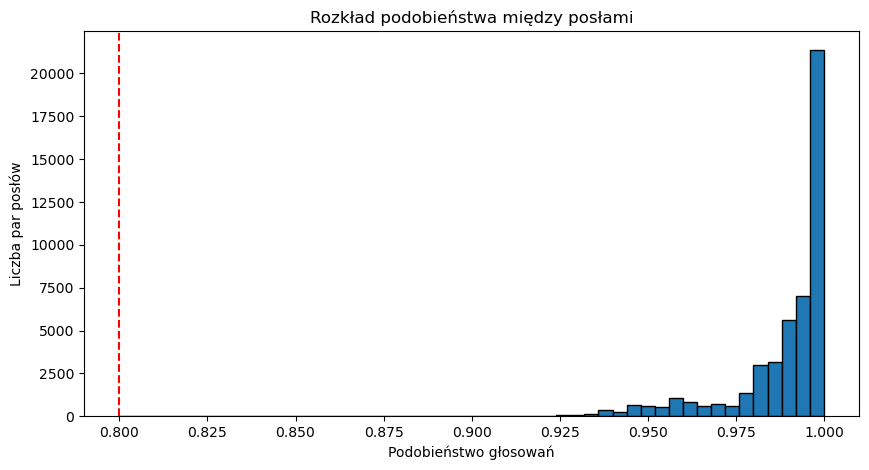

Mediana: 0.994
Średnia: 0.988
% par powyżej 0.5: 100.0%
% par powyżej 0.7: 100.0%


In [13]:
import matplotlib.pyplot as plt

weights = [d["weight"] for a, b, d in G.edges(data=True)]

plt.figure(figsize=(10, 5))
plt.hist(weights, bins=50, edgecolor="black")
plt.xlabel("Podobieństwo głosowań")
plt.ylabel("Liczba par posłów")
plt.title("Rozkład podobieństwa między posłami")
plt.axvline(0.8, color="red", linestyle="--", label="próg 0.8")
plt.savefig("rozklad_wag.png", dpi=150)
plt.show()

# I statystyki
import numpy as np
print(f"Mediana: {np.median(weights):.3f}")
print(f"Średnia: {np.mean(weights):.3f}")
print(f"% par powyżej 0.5: {np.mean(np.array(weights) > 0.5)*100:.1f}%")
print(f"% par powyżej 0.7: {np.mean(np.array(weights) > 0.7)*100:.1f}%")

Wyniki:
Kofederacja jest bardziej antypisowa, niz Razem jest anty KO

Modularity:
modeularity - 0.478
Number of communities - 3

Avg clustering coefficient - 0.99

Network diameter:
Diameter - 3
Radius - 1
Average Path Length - 1.101


In [15]:
# Którzy posłowie mają najwięcej połączeń między klastrami?
for node in G.nodes():
    neighbors = list(G.neighbors(node))
    own_club = posel_meta.loc[node, "klub"]
    cross = [n for n in neighbors 
             if posel_meta.loc[n, "klub"] != own_club]
    if len(cross) > 5:
        print(f"{posel_meta.loc[node, 'nazwisko']} ({own_club}): "
              f"{len(cross)} połączeń między klastrami")

Adamowicz (KO): 86 połączeń między klastrami
Ardanowski (Kukiz15): 190 połączeń między klastrami
Augustyn (KO): 86 połączeń między klastrami
Bartoszewski (PSL-TD): 211 połączeń między klastrami
Bejda (PSL-TD): 211 połączeń między klastrami
Bielawska (KO): 86 połączeń między klastrami
Biernacki (PSL-TD): 211 połączeń między klastrami
Bliźniuk (KO): 86 połączeń między klastrami
Bochenek (KO): 86 połączeń między klastrami
Bodnar (Polska2050-TD): 212 połączeń między klastrami
Bojarski (KO): 86 połączeń między klastrami
Borys (KO): 86 połączeń między klastrami
Bosacki (KO): 86 połączeń między klastrami
Bosak (Konfederacja): 10 połączeń między klastrami
Bosak (Konfederacja): 9 połączeń między klastrami
Buczyńska (Polska2050-TD): 211 połączeń między klastrami
Burkiewicz (Polska2050-TD): 211 połączeń między klastrami
Chmielewski (KO): 86 połączeń między klastrami
Chybicka (KO): 86 połączeń między klastrami
Cichoń (KO): 86 połączeń między klastrami
Cwalina-Śliwowska (Polska2050-TD): 211 połącze

In [ ]:

# Betweenness
betweenness = nx.betweenness_centrality(G, weight="weight", normalized=True)
degree = nx.degree_centrality(G)

# Złącz z metadanymi
df_stats = pd.DataFrame({
    "nazwisko": posel_meta["nazwisko"],
    "klub": posel_meta["klub"],
    "degree": pd.Series(degree),
    "betweenness": pd.Series(betweenness)
})

# Top 10 według betweenness
print(df_stats.nlargest(10, "betweenness")[["nazwisko", "klub", "betweenness", "degree"]])

# Średnia betweenness per klub
print(df_stats.groupby("klub")["betweenness"].mean().sort_values(ascending=False))

        nazwisko     klub  betweenness    degree
456       Ziobro      PiS     0.009547  0.433551
321     Sachajko  Kukiz15     0.008572  0.420479
200        Kukiz  Kukiz15     0.007621  0.065359
250  Mrówczyński      PiS     0.005442  0.450980
90     Gawkowski   Lewica     0.005180  0.535948
369       Szejna   Lewica     0.004652  0.538126
404       Uruski      PiS     0.002261  0.440087
311   Romanowski      PiS     0.002191  0.437908
234      Matecki      PiS     0.001950  0.433551
240        Mejza      PiS     0.001443  0.435730
klub
Kukiz15          0.004050
Lewica           0.000470
PiS              0.000128
Konfederacja     0.000023
PSL-TD           0.000003
Polska2050-TD    0.000002
Razem            0.000002
KO               0.000000
niez.            0.000000
Name: betweenness, dtype: float64


In [ ]:
# Spójność wewnątrz każdego klubu
for klub in posel_meta["klub"].unique():
    czlonkowie = posel_meta[posel_meta["klub"] == klub].index.tolist()
    subgraf = G.subgraph(czlonkowie)
    edges = subgraf.number_of_edges()
    mozliwe = len(czlonkowie) * (len(czlonkowie)-1) / 2
    gestosc = edges / mozliwe if mozliwe > 0 else 0
    print(f"{klub}: gęstość wewnętrzna = {gestosc:.3f}, posłów = {len(czlonkowie)}")

# Średnia waga krawędzi między blokami
koalicja = ["KO", "PSL-TD", "Polska2050-TD", "Lewica", "Razem"]
opozycja = ["PiS", "Konfederacja", "Kukiz15"]

wagi_wewn_koa = []
wagi_wewn_opo = []
wagi_miedzy = []

for a, b, d in G.edges(data=True):
    ka = posel_meta.loc[a, "klub"] if a in posel_meta.index else None
    kb = posel_meta.loc[b, "klub"] if b in posel_meta.index else None
    if not ka or not kb:
        continue
    a_koa = ka in koalicja
    b_koa = kb in koalicja
    if a_koa and b_koa:
        wagi_wewn_koa.append(d["weight"])
    elif not a_koa and not b_koa:
        wagi_wewn_opo.append(d["weight"])
    else:
        wagi_miedzy.append(d["weight"])

print(f"\nŚrednia waga wewnątrz koalicji: {np.mean(wagi_wewn_koa):.3f}")
print(f"Średnia waga wewnątrz opozycji: {np.mean(wagi_wewn_opo):.3f}")
print(f"Średnia waga między blokami: {np.mean(wagi_miedzy):.3f}")
print(f"Krawędzi między blokami: {len(wagi_miedzy)}")

PiS: gęstość wewnętrzna = 1.000, posłów = 190
KO: gęstość wewnętrzna = 1.000, posłów = 157
Kukiz15: gęstość wewnętrzna = 0.833, posłów = 4
PSL-TD: gęstość wewnętrzna = 1.000, posłów = 32
Konfederacja: gęstość wewnętrzna = 1.000, posłów = 18
Polska2050-TD: gęstość wewnętrzna = 1.000, posłów = 32
Lewica: gęstość wewnętrzna = 1.000, posłów = 21
niez.: gęstość wewnętrzna = 0.000, posłów = 1
Razem: gęstość wewnętrzna = 1.000, posłów = 5

Średnia waga wewnątrz koalicji: 0.985
Średnia waga wewnątrz opozycji: 0.992
Średnia waga między blokami: 0.991
Krawędzi między blokami: 242
